# Project 2: Prairie Crop Tracker

**Setting**:	Selection

**County**:	Lyon County

**State**:	Minnesota

**Crop**:	Corn for grain

**Yield measurement**:	Bushels per acre

**Historical period**:	At least 20 years

**Weather focus**:	June rainfall and temperature

**Research question**: Do wet or dry Junes affect corn yields in Lyon County, Minnesota?



Before I start collecting and processing data, I will set up Colab using the cell below. Pandas will be used to organize said information into tables, matplotlib will visualize the results, and SQLite will be used to store and query the cleaned datasets. Separate olders to keep the raw and cleaned data will be created. I expect the imports and folder creation to succeed.

In [1]:
##Step 1: Setup
import requests
import pandas as pd
import matplotlib.pyplot as plt
import sqlite3
import json
from pathlib import Path

# Create folders for storing data
Path("data/raw").mkdir(parents=True, exist_ok=True)
Path("data/clean").mkdir(parents=True, exist_ok=True)
Path("charts").mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully.")
print("Project folders created.")

Libraries imported successfully.
Project folders created.


Libraries were imported successfully, and so was creating the project folders.

##Step 2.0: Obtain USDA/NASS API Key
I added the USDA/NASS API key to Colab Secrets, then gave it notebook access.

The cell below connects the USDA NASS Quick Stats API using the key stored in Colab Secrets. Corn grain yield data for Lyon County, MN will be requested. The cell below this one will be used to test the API. The key should be loaded successfully, along with the test for the key.

In [2]:
##Step 2.1.1: Load API Key

from google.colab import userdata

API_KEY = userdata.get("NASS_API_KEY")

if API_KEY:
    print("USDA API key loaded successfully.")
else:
    print("API key not found. Check Colab Secrets.")

USDA API key loaded successfully.


The API key was loaded successfully.

In [3]:
##Step 2.1.2: Test the API
url = "https://quickstats.nass.usda.gov/api/api_GET/"

params = {
    "key": API_KEY,
    "source_desc": "SURVEY",
    "commodity_desc": "CORN",
    "statisticcat_desc": "YIELD",
    "agg_level_desc": "COUNTY",
    "state_alpha": "MN",
    "county_name": "LYON",
    "year__GE": 2020,
    "format": "JSON"
}

try:
    response = requests.get(url, params=params, timeout=30)
    print("Status code:", response.status_code)

    response.raise_for_status()
    raw_data = response.json()

    # Save the original API response
    with open("data/raw/nass_test.json", "w") as file:
        json.dump(raw_data, file, indent=4)

    records = raw_data.get("data", [])

    print("Records retrieved:", len(records))

    if records:
        test_df = pd.DataFrame(records)
        print("\nAvailable yield descriptions:")
        print(test_df["short_desc"].unique())

        display(test_df.head())

    else:
        print("No records returned.")
        print(raw_data)

except requests.exceptions.RequestException as error:
    print("API request failed:", error)

Status code: 200
Records retrieved: 4

Available yield descriptions:
['CORN, GRAIN - YIELD, MEASURED IN BU / ACRE'
 'CORN, SILAGE - YIELD, MEASURED IN TONS / ACRE']


,asd_code,state_alpha,location_desc,zip_5,county_ansi,util_practice_desc,agg_level_desc,county_code,begin_code,CV (%),...,statisticcat_desc,year,sector_desc,congr_district_code,watershed_desc,prodn_practice_desc,Value,domaincat_desc,short_desc,freq_desc
0,70,MN,"MINNESOTA, SOUTHWEST, LYON",,083,GRAIN,COUNTY,083,00,2.9,...,YIELD,2022,CROPS,,,ALL PRODUCTION PRACTICES,176,NOT SPECIFIED,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",ANNUAL
1,70,MN,"MINNESOTA, SOUTHWEST, LYON",,083,GRAIN,COUNTY,083,00,3.2,...,YIELD,2021,CROPS,,,ALL PRODUCTION PRACTICES,162.8,NOT SPECIFIED,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",ANNUAL
2,70,MN,"MINNESOTA, SOUTHWEST, LYON",,083,GRAIN,COUNTY,083,00,2.0,...,YIELD,2020,CROPS,,,ALL PRODUCTION PRACTICES,205.2,NOT SPECIFIED,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",ANNUAL
3,70,MN,"MINNESOTA, SOUTHWEST, LYON",,083,SILAGE,COUNTY,083,00,4.8,...,YIELD,2022,CROPS,,,ALL PRODUCTION PRACTICES,20,NOT SPECIFIED,"CORN, SILAGE - YIELD, MEASURED IN TONS / ACRE",ANNUAL


The API key was loaded successfully, and the test for the key returned a status code 200 and 4 records retrieved.

The cell below identifies the exact years and removes silage records. I don't know how to explain this further since it's quite self explantory already.

In [4]:
##Step 2.1.3: Inspect and Filter the Results

# Display the years returned by the API
print("Years returned:")
print(test_df["year"].tolist())

# Keep only corn grain measured in bushels per acre
grain_df = test_df[
    test_df["short_desc"] == "CORN, GRAIN - YIELD, MEASURED IN BU / ACRE"
].copy()

# Convert yield values to numeric
grain_df["Value"] = pd.to_numeric(grain_df["Value"], errors="coerce")

# Display relevant columns
display(grain_df[["year", "county_name", "Value", "unit_desc"]])


Years returned:
[2022, 2021, 2020, 2022]


,year,county_name,Value,unit_desc
0,2022,LYON,176.0,BU / ACRE
1,2021,LYON,162.8,BU / ACRE
2,2020,LYON,205.2,BU / ACRE


The years 2020, 2021, and 2022 remain, and silage records were excluded.

After successfully testing the API, the date range will be expanded to starting from 2000 instead of 2020. This will retrieve more historical data on corn yeilds. The year filter will be used to request data starting from 2000 while retaining county and crop filters. I should get more records retrieved and the years available as a result.

In [5]:
##Step 2.2: Expand Historical Data Request
params["year__GE"] = 2000

try:
    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()

    historical_data = response.json()

    # Save the original response unchanged
    with open("data/raw/nass_historical.json", "w") as file:
        json.dump(historical_data, file, indent=4)

    historical_df = pd.DataFrame(historical_data.get("data", []))

    print("Historical records retrieved:", len(historical_df))

    if not historical_df.empty:
        print("Years available:")
        print(sorted(historical_df["year"].unique()))

except requests.exceptions.RequestException as error:
    print("Request failed:", error)
    print(response.text)

Historical records retrieved: 32
Years available:
[np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022)]


32 historical records were retrieved, along with the years available.

The cell below removes corn silage records since this project's focus is on corn harvested for grain. The short_desc column will be used to filter by identifying the crop measurements. This cell will also output records per year, along with a table excluding silage.

In [6]:
##Step 2.3: Filter the Historical Dataset

# Inspect the different yield descriptions
print(historical_df["short_desc"].value_counts())

# Keep only corn grain records
corn_df = historical_df[
    historical_df["short_desc"] ==
    "CORN, GRAIN - YIELD, MEASURED IN BU / ACRE"
].copy()

# Convert yield values to numeric
corn_df["Value"] = pd.to_numeric(
    corn_df["Value"], errors="coerce"
)

# Sort by year
corn_df["year"] = pd.to_numeric(corn_df["year"])
corn_df = corn_df.sort_values("year")

print("\nCorn grain records:", len(corn_df))
print("Unique years:", corn_df["year"].nunique())

# Check for multiple records in the same year
print("\nRecords per year:")
print(corn_df["year"].value_counts().sort_index())

display(corn_df[["year", "Value", "unit_desc", "short_desc"]])

short_desc
CORN, GRAIN - YIELD, MEASURED IN BU / ACRE       23
CORN, SILAGE - YIELD, MEASURED IN TONS / ACRE     9
Name: count, dtype: int64

Corn grain records: 23
Unique years: 23

Records per year:
year
2000    1
2001    1
2002    1
2003    1
2004    1
2005    1
2006    1
2007    1
2008    1
2009    1
2010    1
2011    1
2012    1
2013    1
2014    1
2015    1
2016    1
2017    1
2018    1
2019    1
2020    1
2021    1
2022    1
Name: count, dtype: int64


,year,Value,unit_desc,short_desc
22,2000,140.0,BU / ACRE,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE"
21,2001,133.0,BU / ACRE,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE"
20,2002,153.0,BU / ACRE,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE"
19,2003,140.0,BU / ACRE,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE"
18,2004,160.0,BU / ACRE,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE"
17,2005,180.0,BU / ACRE,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE"
16,2006,165.0,BU / ACRE,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE"
15,2007,150.0,BU / ACRE,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE"
14,2008,157.0,BU / ACRE,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE"
13,2009,174.0,BU / ACRE,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE"


There is 1 record per year from 2000 to 2022, and a table with those years excluding silage.

The cell below will be used to examine how the raw USDA dataset organizes its information. It will be used to examine the number of rows and columns, data types, and missing values. This is done because the original API response contains multiple corn measurements, which might need to be converted. I expect to the output to contain the number of rows and columns, data types, and missing values.

In [7]:
  ##Step 3.1: Examine Dataset Structure
# Examine the original USDA dataset
print("Dataset dimensions:", historical_df.shape)

print("\nColumn names:")
print(historical_df.columns.tolist())

print("\nData types:")
print(historical_df.dtypes)

print("\nMissing values per column:")
print(historical_df.isnull().sum())

print("\nYear range:")
print(
    historical_df["year"].min(),
    "to",
    historical_df["year"].max()
)

print("\nFirst five records:")
display(historical_df.head())

Dataset dimensions: (32, 39)

Column names:
['region_desc', 'statisticcat_desc', 'state_fips_code', 'year', 'CV (%)', 'source_desc', 'county_code', 'load_time', 'asd_code', 'watershed_code', 'freq_desc', 'sector_desc', 'state_ansi', 'watershed_desc', 'class_desc', 'country_code', 'week_ending', 'domaincat_desc', 'state_alpha', 'congr_district_code', 'asd_desc', 'location_desc', 'reference_period_desc', 'zip_5', 'unit_desc', 'county_ansi', 'begin_code', 'util_practice_desc', 'commodity_desc', 'short_desc', 'prodn_practice_desc', 'end_code', 'group_desc', 'domain_desc', 'state_name', 'country_name', 'agg_level_desc', 'county_name', 'Value']

Data types:
region_desc              object
statisticcat_desc        object
state_fips_code          object
year                      int64
CV (%)                   object
source_desc              object
county_code              object
load_time                object
asd_code                 object
watershed_code           object
freq_desc           

,region_desc,statisticcat_desc,state_fips_code,year,CV (%),source_desc,county_code,load_time,asd_code,watershed_code,...,short_desc,prodn_practice_desc,end_code,group_desc,domain_desc,state_name,country_name,agg_level_desc,county_name,Value
0,,YIELD,27,2022,2.9,SURVEY,083,2024-02-23 15:00:00.000,70,00000000,...,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",ALL PRODUCTION PRACTICES,00,FIELD CROPS,TOTAL,MINNESOTA,UNITED STATES,COUNTY,LYON,176
1,,YIELD,27,2021,3.2,SURVEY,083,2024-02-23 15:00:00.000,70,00000000,...,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",ALL PRODUCTION PRACTICES,00,FIELD CROPS,TOTAL,MINNESOTA,UNITED STATES,COUNTY,LYON,162.8
2,,YIELD,27,2020,2.0,SURVEY,083,2024-02-23 15:00:00.000,70,00000000,...,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",ALL PRODUCTION PRACTICES,00,FIELD CROPS,TOTAL,MINNESOTA,UNITED STATES,COUNTY,LYON,205.2
3,,YIELD,27,2019,,SURVEY,083,2024-02-23 15:00:00.000,70,00000000,...,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",ALL PRODUCTION PRACTICES,00,FIELD CROPS,TOTAL,MINNESOTA,UNITED STATES,COUNTY,LYON,172.2
4,,YIELD,27,2018,,SURVEY,083,2024-02-23 15:00:00.000,70,00000000,...,"CORN, GRAIN - YIELD, MEASURED IN BU / ACRE",ALL PRODUCTION PRACTICES,00,FIELD CROPS,TOTAL,MINNESOTA,UNITED STATES,COUNTY,LYON,179.9


There are no missing values, 32 rows and 39 columns, no missing values per column, and all data types are object with the exception of year being int64. Value is stored as an object when it should be numeric.

The cell below checks if there are any data quality issues. It does this by checking for duplicate records, duplicate years, and missing values. It will also check the yield for missing values, data types, and the original values. I expect to see errors, the yield data type, and the original yield values.

In [8]:
##Step 3.2: Investigate Data Quality
# Check duplicate records
print("Duplicate rows:", historical_df.duplicated().sum())

# Check duplicate years for corn grain
print("\nDuplicate grain years:",
      corn_df["year"].duplicated().sum())

# Check missing yield values
print("\nMissing yield values:",
      corn_df["Value"].isnull().sum())

# Inspect yield data types
print("\nYield column data type:")
print(corn_df["Value"].dtype)

# Inspect the original yield values
print("\nOriginal yield values:")
print(corn_df["Value"].tolist())


Duplicate rows: 0

Duplicate grain years: 0

Missing yield values: 0

Yield column data type:
float64

Original yield values:
[140.0, 133.0, 153.0, 140.0, 160.0, 180.0, 165.0, 150.0, 157.0, 174.0, 168.6, 147.8, 152.6, 150.1, 152.4, 193.3, 203.5, 183.0, 179.9, 172.2, 205.2, 162.8, 176.0]


There are no duplicates in any checked values, the yield column data type is int64, and all of the original values are stored as text.

The cell below creates a cleaned dataset by only using the fields relevant for analysis, and excluded silage. The year and value for corn yield will converted to numeric types. Records will be sorted chronologically. The cell should output a cleaned dataset that uses bushels per acre as a unit, and presents the yield values numerically.

In [9]:
##Step 4.1: Create Cleaned Dataset
# Create a cleaned copy of the original USDA data
corn_clean = historical_df[
    historical_df["short_desc"] ==
    "CORN, GRAIN - YIELD, MEASURED IN BU / ACRE"
].copy()

# Keep only the fields needed for analysis
corn_clean = corn_clean[
    ["year", "Value", "unit_desc", "county_name", "state_name"]
]

# Convert year and yield to numeric types
corn_clean["year"] = pd.to_numeric(corn_clean["year"])
corn_clean["Value"] = pd.to_numeric(corn_clean["Value"])

# Sort records chronologically
corn_clean = corn_clean.sort_values("year").reset_index(drop=True)

# Display the cleaned dataset
display(corn_clean)

print("Cleaned dataset dimensions:", corn_clean.shape)
print("\nData types:")
print(corn_clean.dtypes)

,year,Value,unit_desc,county_name,state_name
0,2000,140.0,BU / ACRE,LYON,MINNESOTA
1,2001,133.0,BU / ACRE,LYON,MINNESOTA
2,2002,153.0,BU / ACRE,LYON,MINNESOTA
3,2003,140.0,BU / ACRE,LYON,MINNESOTA
4,2004,160.0,BU / ACRE,LYON,MINNESOTA
5,2005,180.0,BU / ACRE,LYON,MINNESOTA
6,2006,165.0,BU / ACRE,LYON,MINNESOTA
7,2007,150.0,BU / ACRE,LYON,MINNESOTA
8,2008,157.0,BU / ACRE,LYON,MINNESOTA
9,2009,174.0,BU / ACRE,LYON,MINNESOTA


Cleaned dataset dimensions: (23, 5)

Data types:
year             int64
Value          float64
unit_desc       object
county_name     object
state_name      object
dtype: object


I got a cleaned dataset where year and value are numeric. There are 23 rows and 5 columns.

The cell below verifies the data in the cleaned dataset. This is done by checking for any missing values and duplicate years. The year coverage and unqiue years will also be printed, along with the yield summary. I expect to see missing values listed, the amount of duplicate years, year coverage, and the yield summary.

In [10]:
##Step 4.2: Verifying Cleaned Dataset
# Verify the cleaned dataset
print("Missing values:")
print(corn_clean.isnull().sum())

print("\nDuplicate years:", corn_clean["year"].duplicated().sum())

print("\nYear coverage:")
print(corn_clean["year"].min(), "to", corn_clean["year"].max())

print("\nNumber of unique years:", corn_clean["year"].nunique())

print("\nYield summary:")
print(corn_clean["Value"].describe())

Missing values:
year           0
Value          0
unit_desc      0
county_name    0
state_name     0
dtype: int64

Duplicate years: 0

Year coverage:
2000 to 2022

Number of unique years: 23

Yield summary:
count     23.000000
mean     165.191304
std       19.660017
min      133.000000
25%      151.250000
50%      162.800000
75%      177.950000
max      205.200000
Name: Value, dtype: float64


There are no missing values, no duplicate years, 2000-2022 coverage, and 23 unique years. The yield summary shows the lowestb yield as 133 bushels per acre, and the highest yield as 205 bu/acre, with 165.191304 bu/acre as the mean. The datatypes are also correct.

The cell below is for testing the Open-Meteo API using Marshall, MN's coordinates. This test retrieves seven days of data from June 2000, requesting precipitation and temperature, with precipitation measured in inches and temperatue measured in Fahrenheit. I should get seven days worth of the aformentioned data, and it should be saved into data/raw/.

In [11]:
##Step 5.1: Testing Open-Meteo API
import requests
import json

weather_url = "https://archive-api.open-meteo.com/v1/archive"

weather_params = {
    "latitude": 44.44889,
    "longitude": -95.78944,
    "start_date": "2000-06-01",
    "end_date": "2000-06-07",
    "daily": "precipitation_sum,temperature_2m_max,temperature_2m_mean",
    "temperature_unit": "fahrenheit",
    "precipitation_unit": "inch",
    "timezone": "America/Chicago"
}

weather_response = requests.get(weather_url, params=weather_params)

print("Status code:", weather_response.status_code)

weather_data = weather_response.json()

if weather_response.status_code == 200:
    with open("data/raw/weather_test.json", "w") as file:
        json.dump(weather_data, file, indent=4)

    print("\nResponse keys:", weather_data.keys())
    print("\nDaily weather data:")
    display(pd.DataFrame(weather_data["daily"]))
else:
    print(weather_data)

Status code: 200

Response keys: dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'daily_units', 'daily'])

Daily weather data:


,time,precipitation_sum,temperature_2m_max,temperature_2m_mean
0,2000-06-01,0.461,69.1,60.0
1,2000-06-02,0.000,62.2,55.5
2,2000-06-03,0.465,68.8,58.1
3,2000-06-04,0.370,57.9,54.7
4,2000-06-05,0.000,65.1,55.2
5,2000-06-06,0.000,72.4,61.5
6,2000-06-07,0.000,83.7,72.0


I got seven days worth of precpitation and temperature data from 2000-06-01 to 2000-06-07. The test file was successfully saved into data/raw/.

After successfully testing the Open-Meteo API with the cell above, the cell below will retrieve the full 23 years of historical data from the same period as the crop yield dataset. Once done, it will be saved into /data/raw/ like the test file. I expect the 23 years world of data to be successfully retrieved and stored.

In [12]:
##Step 5.2: Retrieve Historical Data from 2000 to 2022
weather_params["start_date"] = "2000-01-01"
weather_params["end_date"] = "2022-12-31"

weather_response = requests.get(weather_url, params=weather_params)

print("Status code:", weather_response.status_code)

weather_data = weather_response.json()

if weather_response.status_code == 200:
    with open("data/raw/weather_historical.json", "w") as file:
        json.dump(weather_data, file, indent=4)

    print("Weather data saved successfully.")

    print("\nNumber of daily records:",
          len(weather_data["daily"]["time"]))

    print("\nFirst date:", weather_data["daily"]["time"][0])
    print("Last date:", weather_data["daily"]["time"][-1])
else:
    print(weather_data)

Status code: 200
Weather data saved successfully.

Number of daily records: 8401

First date: 2000-01-01
Last date: 2022-12-31


Data from 2000-01-01 to 2022-12-31 with 8401 daily records was saved to data/raw/ successfully.

The cell below extracts the daily weather data from the API response and then converts them into a DataFrame. The date is converted into datetime format, and the first five rows are displayed. I expect the first 5 rows to be printed, date to become datetime, and missing values be displayed.

In [13]:
##Step 5.3: Convert Daily Weather Data into a Dataframe and Convert Column into Datetime
# Convert daily weather data into a DataFrame
weather_df = pd.DataFrame(weather_data["daily"])

# Convert the date column to datetime
weather_df["time"] = pd.to_datetime(weather_df["time"])

# Display the first five records
display(weather_df.head())

print("Dataset dimensions:", weather_df.shape)

print("\nData types:")
print(weather_df.dtypes)

print("\nMissing values:")
print(weather_df.isnull().sum())

,time,precipitation_sum,temperature_2m_max,temperature_2m_mean
0,2000-01-01,0.000,32.2,26.7
1,2000-01-02,0.000,31.1,26.8
2,2000-01-03,0.000,27.7,23.3
3,2000-01-04,0.000,17.9,10.9
4,2000-01-05,0.094,32.9,25.3


Dataset dimensions: (8401, 4)

Data types:
time                   datetime64[ns]
precipitation_sum             float64
temperature_2m_max            float64
temperature_2m_mean           float64
dtype: object

Missing values:
time                   0
precipitation_sum      0
temperature_2m_max     0
temperature_2m_mean    0
dtype: int64


The first 5 rows of data looks correct, datetime was successfully converted to datetime, and there are no missing values.

The cell below will calculate these three useful measurements for each year. That being June precipitation, June mean temperature, and May to September precipitation. These measurements are used because May to September is the growing season. I expect to see a table containing these measurements annually.

In [14]:
##Step 5.4: Create Annual Weather Summaries
# Extract year and month from each date
weather_df["year"] = weather_df["time"].dt.year
weather_df["month"] = weather_df["time"].dt.month

# Select June observations
june_df = weather_df[weather_df["month"] == 6]

# Calculate annual June weather summaries
june_summary = june_df.groupby("year").agg(
    june_precipitation=("precipitation_sum", "sum"),
    june_mean_temperature=("temperature_2m_mean", "mean")
).reset_index()

# Select May through September observations
growing_season_df = weather_df[
    weather_df["month"].between(5, 9)
]

# Calculate total growing-season precipitation
growing_season_summary = growing_season_df.groupby("year").agg(
    may_sep_precipitation=("precipitation_sum", "sum")
).reset_index()

# Combine the annual weather summaries
weather_annual = june_summary.merge(
    growing_season_summary,
    on="year"
)

display(weather_annual.head(10))

print("Annual weather summary dimensions:", weather_annual.shape)

,year,june_precipitation,june_mean_temperature,may_sep_precipitation
0,2000,3.230,66.390000,14.834
1,2001,6.103,67.620000,13.794
2,2002,4.252,71.170000,18.756
3,2003,5.063,65.880000,16.330
4,2004,5.382,64.023333,20.714
5,2005,4.662,70.793333,15.608
6,2006,2.227,70.076667,10.476
7,2007,2.280,71.213333,17.095
8,2008,4.941,67.090000,16.080
9,2009,3.932,66.376667,14.184


Annual weather summary dimensions: (23, 4)


The annual summary table lists all three measurements per year, with dimensions of 23 columns and 4 rows.

The cell below will merge the datasets for weather and annunal corn yield via the year column. This should result in one row per year, with both crop yield and weather together. I expect both datasets to be successfully merged as described.

In [15]:
##Step 6.1: Merging Datasets
# Select the columns needed from the crop-yield dataset
yield_data = corn_clean[["year", "Value"]].copy()

# Rename Value for clarity
yield_data = yield_data.rename(
    columns={"Value": "corn_yield_bu_acre"}
)

# Merge crop yields with annual weather summaries
combined_df = yield_data.merge(
    weather_annual,
    on="year",
    how="inner"
)

# Sort chronologically
combined_df = combined_df.sort_values("year").reset_index(drop=True)

# Display the combined dataset
display(combined_df)

print("Combined dataset dimensions:", combined_df.shape)

,year,corn_yield_bu_acre,june_precipitation,june_mean_temperature,may_sep_precipitation
0,2000,140.0,3.230,66.390000,14.834
1,2001,133.0,6.103,67.620000,13.794
2,2002,153.0,4.252,71.170000,18.756
3,2003,140.0,5.063,65.880000,16.330
4,2004,160.0,5.382,64.023333,20.714
5,2005,180.0,4.662,70.793333,15.608
6,2006,165.0,2.227,70.076667,10.476
7,2007,150.0,2.280,71.213333,17.095
8,2008,157.0,4.941,67.090000,16.080
9,2009,174.0,3.932,66.376667,14.184


Combined dataset dimensions: (23, 5)


Both datasets were successfully merged, with 23 columns and 5 rows.

The merged dataset will noe be verified. The cell below will check for missing values, duplicate years, and year coverage. This is necessary to confirm that both datasets combined correctly. I expect no errors to be found.

In [16]:
##6.2: Verify Merged Dataset
# Check the merged dataset
print("Missing values:")
print(combined_df.isnull().sum())

print("\nDuplicate years:", combined_df["year"].duplicated().sum())

print("\nYear coverage:")
print(combined_df["year"].min(), "to", combined_df["year"].max())

print("\nNumber of unique years:", combined_df["year"].nunique())

print("\nData types:")
print(combined_df.dtypes)

Missing values:
year                     0
corn_yield_bu_acre       0
june_precipitation       0
june_mean_temperature    0
may_sep_precipitation    0
dtype: int64

Duplicate years: 0

Year coverage:
2000 to 2022

Number of unique years: 23

Data types:
year                       int64
corn_yield_bu_acre       float64
june_precipitation       float64
june_mean_temperature    float64
may_sep_precipitation    float64
dtype: object


Both datasets were indeed merged without errors.

##Step 7.0: Analyze Relationship Between Weather and Crop Yield
I will calculate the long-term yield trend since the yields can improve over time due to factors unrelated to weather. A straight line trend will estimate expected yield, then it will be compared against the actual yield to get the yield anomaly. This is needed to show the difference between the actual yield and trend yield, which will be compared against environmental factors, such June rainfall, to answer how this affects corn yields.

###Yield Anomaly = Actual Yield - Trend Yield

Positive Result = Above Long-Term Trend

Negative Result = Below Long-Term trend

The cell below calculates the trend yield using polyfit() from numpy to fit a linear trend through actual corn yields. The estimated trend yield for each year is calculated, then subtracted from the actual yield to get the yield anomaly. I should get a table with rows for trend yield and yield anomaly.

In [17]:
##7.1: Calculate Trend Yield and Yield Anomaly
import numpy as np

# Fit a linear trend to annual corn yields
slope, intercept = np.polyfit(
    combined_df["year"],
    combined_df["corn_yield_bu_acre"],
    1
)

# Calculate the estimated yield for each year
combined_df["trend_yield"] = (
    slope * combined_df["year"] + intercept
)

# Calculate yield anomalies
combined_df["yield_anomaly"] = (
    combined_df["corn_yield_bu_acre"] -
    combined_df["trend_yield"]
)

print("Trend slope:", slope)
print("Trend intercept:", intercept)

display(
    combined_df[
        ["year", "corn_yield_bu_acre",
         "trend_yield", "yield_anomaly"]
    ].round(2)
)

Trend slope: 1.8446640316205578
Trend intercept: -3544.4280632411155


,year,corn_yield_bu_acre,trend_yield,yield_anomaly
0,2000,140.0,144.90,-4.90
1,2001,133.0,146.74,-13.74
2,2002,153.0,148.59,4.41
3,2003,140.0,150.43,-10.43
4,2004,160.0,152.28,7.72
5,2005,180.0,154.12,25.88
6,2006,165.0,155.97,9.03
7,2007,150.0,157.81,-7.81
8,2008,157.0,159.66,-2.66
9,2009,174.0,161.50,12.50


I have a table with every year's actual yield, trend yield, and yield anomaly. The trend slope is 1.8446640316205578, and trend intercept is -3544.4280632411155.

The 23 years of June's rainfall will be categorized into three categories based on:


1. Dry: Bottom 25%
2. Normal: Middle 50%
3. Wet: Top 25%

The reason is that this allows the comparison of long-term trends over solely comparing annunal raw yields.

The cell below will perform this classification based on the above thresholds. I expect to see how many Junes were normal, wet, and dry.

In [18]:
##Step 7.2: Classify June Rainfall as Dry, Normal, or Wet
# Calculate June rainfall percentile thresholds
dry_threshold = combined_df["june_precipitation"].quantile(0.25)
wet_threshold = combined_df["june_precipitation"].quantile(0.75)

print("Dry threshold:", round(dry_threshold, 3), "inches")
print("Wet threshold:", round(wet_threshold, 3), "inches")

# Assign rainfall categories
combined_df["rainfall_category"] = np.select(
    [
        combined_df["june_precipitation"] <= dry_threshold,
        combined_df["june_precipitation"] >= wet_threshold
    ],
    [
        "Dry",
        "Wet"
    ],
    default="Normal"
)

# Display the classified years
display(
    combined_df[
        ["year", "june_precipitation",
         "rainfall_category", "corn_yield_bu_acre",
         "yield_anomaly"]
    ].round(2)
)

print("\nYears in each rainfall category:")
print(combined_df["rainfall_category"].value_counts())

Dry threshold: 2.983 inches
Wet threshold: 5.534 inches


,year,june_precipitation,rainfall_category,corn_yield_bu_acre,yield_anomaly
0,2000,3.23,Normal,140.0,-4.90
1,2001,6.10,Wet,133.0,-13.74
2,2002,4.25,Normal,153.0,4.41
3,2003,5.06,Normal,140.0,-10.43
4,2004,5.38,Normal,160.0,7.72
5,2005,4.66,Normal,180.0,25.88
6,2006,2.23,Dry,165.0,9.03
7,2007,2.28,Dry,150.0,-7.81
8,2008,4.94,Normal,157.0,-2.66
9,2009,3.93,Normal,174.0,12.50



Years in each rainfall category:
rainfall_category
Normal    11
Wet        6
Dry        6
Name: count, dtype: int64


According to this classification system, there are 11 normal Junes, 6 wet Junes, and 6 dry Junes.

The cell below compares average yield anomalies by rainfall category. It will group years by the June rainfall categories of normal, wet, and dry. This helps answer if wet or dry Junes correspond with lower corn yields in Lyon County. I should see how high or low average corn yields were depending on average rainfall.

In [19]:
##Step 7.3: Compare Yield Anomalies by June Rainfall Category
# Compare average yield anomalies by rainfall category
rainfall_comparison = combined_df.groupby(
    "rainfall_category"
).agg(
    average_yield_anomaly=("yield_anomaly", "mean"),
    average_corn_yield=("corn_yield_bu_acre", "mean"),
    average_june_rainfall=("june_precipitation", "mean"),
    number_of_years=("year", "count")
).reset_index()

display(rainfall_comparison.round(2))

,rainfall_category,average_yield_anomaly,average_corn_yield,average_june_rainfall,number_of_years
0,Dry,-8.55,163.10,2.11,6
1,Normal,10.23,171.73,4.21,11
2,Wet,-10.20,155.30,7.45,6


It appears dry and wet rainfall during June is correlated with lower corn yield.

The cell below identifies the three years with the most negative yield anomalies, where actual yields were the furthest under what the trend projected. June rainfall, June mean temperature, and May-September rainfall per year will also be included to add more context to the weather conditions. This is useful for determining if wet or dry June conditions actually cause lower corn yields.

In [20]:
##Step 7.4: Identify the Three Worst Yield Years
# Identify the three worst yield years
worst_years = combined_df.sort_values(
    "yield_anomaly"
).head(3)

# Display yields and weather conditions
display(
    worst_years[
        [
            "year",
            "corn_yield_bu_acre",
            "trend_yield",
            "yield_anomaly",
            "june_precipitation",
            "june_mean_temperature",
            "may_sep_precipitation",
            "rainfall_category"
        ]
    ].round(2)
)

,year,corn_yield_bu_acre,trend_yield,yield_anomaly,june_precipitation,june_mean_temperature,may_sep_precipitation,rainfall_category
21,2021,162.8,183.64,-20.84,1.19,75.62,13.34,Dry
13,2013,150.1,168.88,-18.78,6.11,66.71,18.56,Wet
14,2014,152.4,170.73,-18.33,11.25,67.88,21.62,Wet


Two of the three worst yield years had wet Junes, while the worst year had a dry June.

The chart below shows the actual annual corn yields and linear trend line yield from 2000-2022. This helps visualize long-term changes in yields. I should get a line chart with the actual corn yield plotted, and a dotted line for the linear trend.

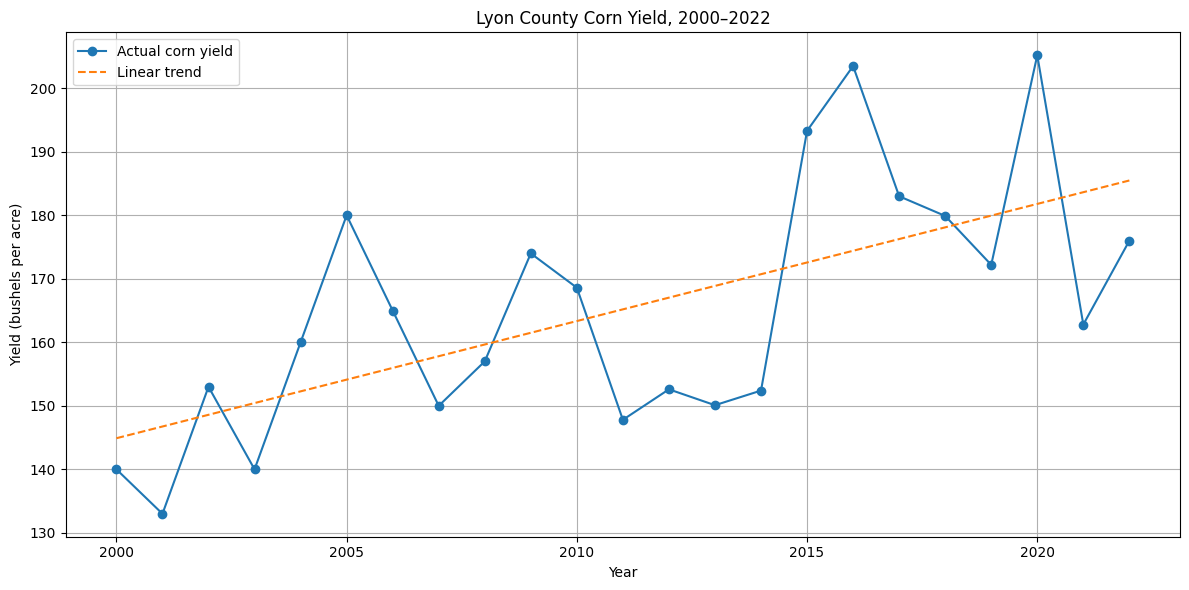

In [21]:
##Step 8.1: Corn Yield Over Time
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    combined_df["year"],
    combined_df["corn_yield_bu_acre"],
    marker="o",
    label="Actual corn yield"
)

plt.plot(
    combined_df["year"],
    combined_df["trend_yield"],
    linestyle="--",
    label="Linear trend"
)

plt.title("Lyon County Corn Yield, 2000–2022")
plt.xlabel("Year")
plt.ylabel("Yield (bushels per acre)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

According to the chart, while the yields generally increased throught the period, the years of 2005, 2009, 2015, 2016, and 2020 all had actual corn yields well above the trend line. This is while the period from 2011 to 2014 had actual yields of well below the trend line.

The chart below shows June rainfall from the 2000-2022, with lines for the dry and wet category thresholds. The categories of "Dry", "Normal", and "Wet" being color coded. I should get a bar chart showing the June precipitation in inches, and color coded to their appropriate categories.

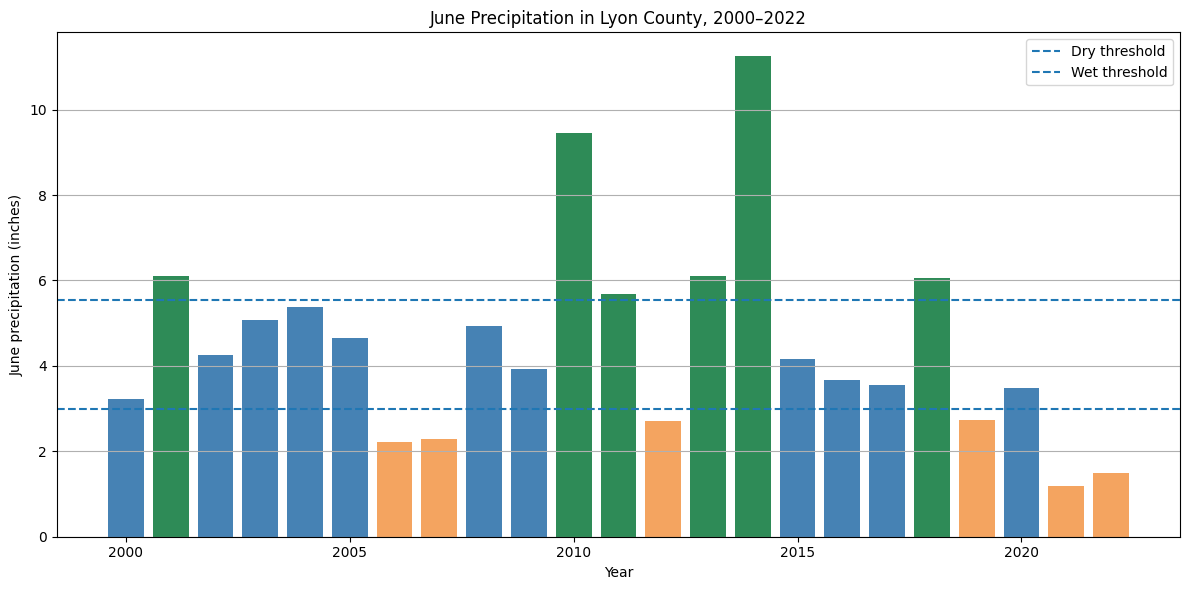

In [22]:
##Step 8.2: June Rainfall by Year
# Assign a color to each rainfall category
category_colors = {
    "Dry": "sandybrown",
    "Normal": "steelblue",
    "Wet": "seagreen"
}

bar_colors = combined_df["rainfall_category"].map(category_colors)

plt.figure(figsize=(12, 6))

plt.bar(
    combined_df["year"],
    combined_df["june_precipitation"],
    color=bar_colors
)

plt.axhline(
    dry_threshold,
    linestyle="--",
    label="Dry threshold"
)

plt.axhline(
    wet_threshold,
    linestyle="--",
    label="Wet threshold"
)

plt.title("June Precipitation in Lyon County, 2000–2022")
plt.xlabel("Year")
plt.ylabel("June precipitation (inches)")
plt.legend()
plt.grid(axis="y")
plt.tight_layout()
plt.show()

The years 2010 and 2014 had the wettest Junes, while the years 2021 and 2022 were the dryest Junes.

The chart below June rainfall with yield anomalies via a scatter splot. The June rainfall categories are represented by color coded points. This chart will help in assessing if extremes in rainfall corresponds with yields that are above or below the trend. I should get a scatter plot showing this.

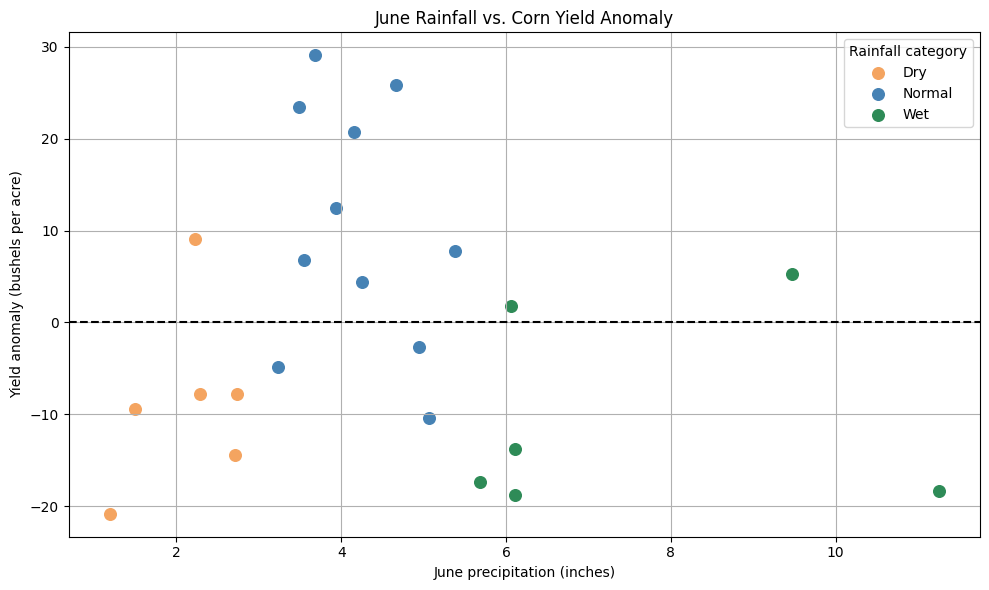

In [23]:
##Step 8.3: June Rainfall vs Yield Anomaly
plt.figure(figsize=(10, 6))

for category, color in category_colors.items():
    subset = combined_df[
        combined_df["rainfall_category"] == category
    ]

    plt.scatter(
        subset["june_precipitation"],
        subset["yield_anomaly"],
        label=category,
        color=color,
        s=70
    )

plt.axhline(0, color="black", linestyle="--")

plt.title("June Rainfall vs. Corn Yield Anomaly")
plt.xlabel("June precipitation (inches)")
plt.ylabel("Yield anomaly (bushels per acre)")
plt.legend(title="Rainfall category")
plt.grid(True)
plt.tight_layout()
plt.show()

Normal years seem to correspond with high positive yield anomalies, while almost all dry and wet years correspond with negative yield anomalies.

##Step 9: Save the Cleaned Data and Create SQLite Database
I decided to have steps 9.1-9.3 in one cell due to their simplicity.

---



**Step 9.1** saves the combined corn yield and weather dataset as a CSV into data/clean/, then prints the types of columns.

**Step 9.2** creates the SQLite database prairie_crop_tracker.db then stores the combined dataset into the crop_weather table. This allows for querying the dataset with SQL, making it easier to retrieve specific years and compare rainfall.

**Step 9.3** verifies the database by displaying 5 rows of it to ensure that data and format are correct.

I expect that the cleaned dataset will be created correctly and saved successfully.

In [24]:
##Step 9.1: Save Final Dataset as CSV
import os

os.makedirs("data/clean", exist_ok=True)

combined_df.to_csv(
    "data/clean/corn_weather_clean.csv",
    index=False
)

print("Cleaned dataset saved successfully.")
print("Rows:", len(combined_df))
print("Columns:", combined_df.columns.tolist())

##Step 9.2: Create SQLite Database
import sqlite3

conn = sqlite3.connect("data/prairie_crop_tracker.db")

combined_df.to_sql(
    "crop_weather",
    conn,
    if_exists="replace",
    index=False
)

print("SQLite database created successfully.")

##Step 9.3: Verify the Database
verification_df = pd.read_sql_query(
    "SELECT * FROM crop_weather LIMIT 5;",
    conn
)

display(verification_df)

Cleaned dataset saved successfully.
Rows: 23
Columns: ['year', 'corn_yield_bu_acre', 'june_precipitation', 'june_mean_temperature', 'may_sep_precipitation', 'trend_yield', 'yield_anomaly', 'rainfall_category']
SQLite database created successfully.


,year,corn_yield_bu_acre,june_precipitation,june_mean_temperature,may_sep_precipitation,trend_yield,yield_anomaly,rainfall_category
0,2000,140.0,3.230,66.390000,14.834,144.900000,-4.900000,Normal
1,2001,133.0,6.103,67.620000,13.794,146.744664,-13.744664,Wet
2,2002,153.0,4.252,71.170000,18.756,148.589328,4.410672,Normal
3,2003,140.0,5.063,65.880000,16.330,150.433992,-10.433992,Normal
4,2004,160.0,5.382,64.023333,20.714,152.278656,7.721344,Normal


The cleaned dataset was saved successfully with 23 rows, with the verified dataset also looking correct.

##Step 10: SQL Querying
Steps 10.1-10.2 are in one cell due to their simplicty.

---

**Step 10.1** queries SQL to identify the three worst years in the cleaned dataset. It will sort by the lowest to highest yield anomalies. June preciptation numbers and June rainfall categories will also be included.

**Step 10.2** compares yields by June rainfall categories by querying the number of years per category, alongside average yield and average rainfall.

I expect to see tables that list the worst years and compares yields by rainfall category respectively.

In [25]:
##Step 10.1: Find the Worst Yields
worst_years = pd.read_sql_query("""
    SELECT
        year,
        corn_yield_bu_acre,
        yield_anomaly,
        june_precipitation,
        rainfall_category
    FROM crop_weather
    ORDER BY yield_anomaly ASC
    LIMIT 3;
""", conn)

display(worst_years)

##Step 10.2: Compare Yields by Rainfall Category
rainfall_comparison = pd.read_sql_query("""
    SELECT
        rainfall_category,
        COUNT(*) AS number_of_years,
        ROUND(AVG(corn_yield_bu_acre), 2) AS average_yield,
        ROUND(AVG(yield_anomaly), 2) AS average_yield_anomaly,
        ROUND(AVG(june_precipitation), 2) AS average_june_rainfall
    FROM crop_weather
    GROUP BY rainfall_category
    ORDER BY CASE rainfall_category
        WHEN 'Dry' THEN 1
        WHEN 'Normal' THEN 2
        WHEN 'Wet' THEN 3
    END;
""", conn)

display(rainfall_comparison)

,year,corn_yield_bu_acre,yield_anomaly,june_precipitation,rainfall_category
0,2021,162.8,-20.837945,1.193,Dry
1,2013,150.1,-18.780632,6.114,Wet
2,2014,152.4,-18.325296,11.248,Wet


,rainfall_category,number_of_years,average_yield,average_yield_anomaly,average_june_rainfall
0,Dry,6,163.10,-8.55,2.11
1,Normal,11,171.73,10.23,4.21
2,Wet,6,155.30,-10.20,7.45


The output is a table showing the three worst yield years and a table comparing yields by rainfall category.

The cell below is a last minute fix to make sure the charts are saved in the correct directory.

## Conclusions

This project investigated the relationship between June precipitation and corn yields in Lyon County, Minnesota, from 2000 through 2022.

The analysis found that corn yields generally increased over the study period. The linear trend showed an average increase of approximately 1.845 bushels per acre per year.

June precipitation appeared to be associated with differences in corn yields. Years classified as having normal June precipitation had an average yield of 171.73 bushels per acre and an average yield anomaly of +10.23 bushels per acre. Dry years averaged 163.10 bushels per acre, with an average anomaly of -8.55. Wet years had the lowest average yield at 155.30 bushels per acre, with an average anomaly of -10.20.

The three worst years relative to the yield trend were 2021, 2013, and 2014. The unusually dry June in 2021 and unusually wet Junes in 2013 and 2014 suggest that both insufficient and excessive precipitation may be associated with reduced yields.

Overall, the results suggest that moderate June precipitation was associated with better corn yields in this dataset. However, June rainfall alone cannot explain all yield variation, and the analysis does not establish a causal relationship.

## Limitations

Several limitations should be considered when interpreting the results:

1. **Limited geographic coverage:** The analysis uses corn yield data from only Lyon County, Minnesota. Results may not represent other counties or agricultural regions.

2. **Limited weather coverage:** Weather observations were obtained using coordinates near Marshall, Minnesota, the county seat. These observations may not represent precipitation and temperature conditions across the entire county.

3. **Limited sample size:** The dataset contains only 23 annual observations from 2000 through 2022. The dry and wet categories each contain only six years, which limits the strength of comparisons.

4. **Other factors affecting crop yields:** Corn yields are influenced by more than June precipitation. Soil conditions, planting dates, growing-season temperatures, pests, agricultural practices, seed varieties, and precipitation during other months may also affect yields.

5. **Simplified trend model:** The analysis uses a linear trend to estimate expected yields. Actual agricultural productivity may not increase at a constant rate over time.

6. **Association does not establish causation:** The observed differences between rainfall categories do not prove that June precipitation caused changes in corn yields.

7. **Historical data coverage:** The available USDA yield records used in this project cover 2000–2022. More recent years are not included in this analysis.

## Data Sources and Attribution

This project used two public data sources:

**1. USDA National Agricultural Statistics Service (NASS) Quick Stats API**

- Website: https://quickstats.nass.usda.gov/
- Used to retrieve historical corn grain yield data for Lyon County, Minnesota.
- The dataset included annual yield measurements in bushels per acre from 2000 through 2022.

**2. Open-Meteo Historical Weather API**

- Website: https://open-meteo.com/en/docs/historical-weather-api
- Used to retrieve historical daily precipitation and temperature observations near Marshall, Minnesota.
- Daily observations were aggregated into annual June precipitation, average June temperature, and May–September precipitation measurements.

**Tools and libraries used:**

- Python
- Pandas for data manipulation and cleaning
- NumPy for numerical calculations and trend estimation
- Matplotlib for data visualization
- SQLite for database storage and SQL queries
- Requests for API communication

The data was retrieved from publicly accessible sources and processed for educational and analytical purposes. The original API responses were preserved in the `data/raw/` directory, while the cleaned and combined dataset was saved in `data/clean/`.

### AI Use Note

I used ChatGPT to help understand the assignment, troubleshoot Python code, and organize parts of the data analysis. I ran the code in Google Colab and used the results from my own datasets to interpret the findings.